# 15 · Hold the gallery fixed and change the motif

Build the gallery with windowed waves. Replace the query motifs by ridges or bars while preserving the same arrangement. Each 8 × 8 tile is in a known frame. Test random cyclic shifts, independent tile contrast flips, and increasing Gaussian noise. The correct label describes the arrangement of axes, with the motif family and tile polarity treated as nuisances.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.core import power, bispectrum
from observables.patterns import homometric
from observables.stage3 import (tile_library, render, tile_q, cyclic_statistics, matrix_profile,
                                crop_census, orbit, FAMILIES, CONDITIONS, METHODS, run)
OUT = ROOT/'results'/'stage3'
OUT.mkdir(exist_ok=True, parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
a, b = homometric()

## Matched controls
Q pair and Q triple compare periodic correlation profiles. Aligned Q compares the full measured sequence over all 12 shifts. Pixel alignment uses the same shifts, with a second baseline independently permitting a sign flip for each tile. That baseline matches the nuisance symmetry of Q. The two unseen motif families share axes and tile geometry with the reference family. There are 48 perturbation trajectories per arrangement. The same shift, signs and noise draw are reused across the motif and severity comparisons.

In [3]:
census,queries,summary=run(OUT)
assert len(queries)==2*48*3*5*5
assert np.allclose(summary[summary.method=='Q pair'].top1,.5)
display(summary.pivot(index=['motif','condition'],columns='method',values='top1')
        .reindex(pd.MultiIndex.from_product([FAMILIES,CONDITIONS],names=['motif','condition'])).round(3))

method                    Q pair  Q triple  aligned Q  aligned pixels  \
motif         condition                                                 
windowed wave clean          0.5     1.000      1.000           1.000   
              tile sign      0.5     1.000      1.000           0.500   
              noise 0.35     0.5     1.000      1.000           0.458   
              noise 1.0      0.5     1.000      1.000           0.458   
              noise 2.0      0.5     0.854      0.833           0.458   
ridge         clean          0.5     1.000      1.000           1.000   
              tile sign      0.5     1.000      1.000           0.500   
              noise 0.35     0.5     1.000      1.000           0.458   
              noise 1.0      0.5     1.000      0.979           0.458   
              noise 2.0      0.5     0.667      0.688           0.500   
bar           clean          0.5     1.000      1.000           1.000   
              tile sign      0.5     1.000      1.000           0.500   
              noise 0.35     0.5     1.000      1.000           0.458   
              noise 1.0      0.5     1.000      1.000           0.458   
              noise 2.0      0.5     0.677      0.698           0.510   

method                    aligned sign-free patches  
motif         condition                              
windowed wave clean                           1.000  
              tile sign                       1.000  
              noise 0.35                      1.000  
              noise 1.0                       1.000  
              noise 2.0                       1.000  
ridge         clean                           1.000  
              tile sign                       1.000  
              noise 0.35                      1.000  
              noise 1.0                       1.000  
              noise 2.0                       0.979  
bar           clean                           1.000  
              tile sign                       1.000  
              noise 0.35                      1.000  
              noise 1.0                       1.000  
              noise 2.0                       1.000

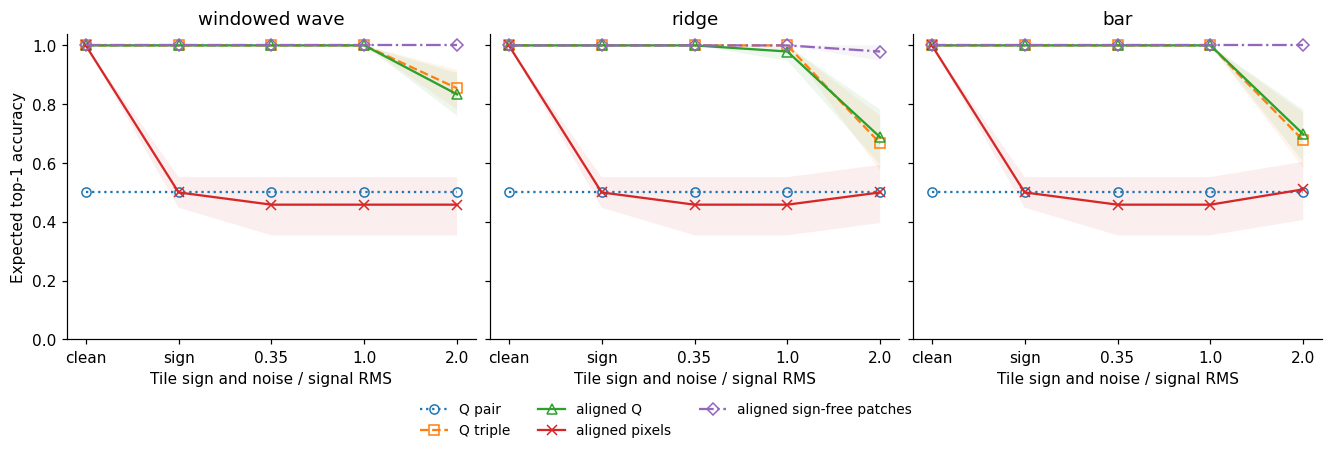

In [5]:
fig,axes=plt.subplots(1,3,figsize=(12,4),sharey=True)
style={'Q pair':'o:','Q triple':'s--','aligned Q':'^-','aligned pixels':'x-','aligned sign-free patches':'D-.'}
for ax,family in zip(axes,FAMILIES):
    for method in METHODS:
        z=summary[(summary.motif==family)&(summary.method==method)].set_index('condition').loc[list(CONDITIONS)]
        x=np.arange(len(z))
        ax.plot(x,z.top1,style[method],label=method,markerfacecolor='none')
        ax.fill_between(x,z.low95.to_numpy(),z.high95.to_numpy(),alpha=.08)
    ax.set(title=family,ylim=(0,1.04),xticks=x,xticklabels=['clean','sign','0.35','1.0','2.0'],
           xlabel='Tile sign and noise / signal RMS')
axes[0].set_ylabel('Expected top-1 accuracy')
fig.legend(*axes[-1].get_legend_handles_labels(),loc='outside lower center',ncol=3,frameon=False,fontsize=9)
show('15_motif_transfer')

## Uncertainty and scope
Top-1 ties split credit. Bands are marginal 95% percentile intervals from 4,000 paired, stratified resamples of the 96 perturbation trajectories. The estimates condition on two fixed arrangements and the specified motifs. They do not estimate population recognition accuracy. The clean and sign conditions use zero noise. The numerical noise labels are standard deviation divided by the clean image RMS. The final condition is a stress test, with noise standard deviation twice the signal RMS.

Perfect separation of a clean collision is a statement about representational capacity. The noise experiment asks a different question about estimation. Compare the triplet profile both to pair pooling and to a baseline with access to the full ordered field.

In [7]:
z=summary[summary.condition=='noise 2.0'].set_index(['motif','method'])
display(z.loc[(slice(None),['Q triple','aligned Q','aligned sign-free patches']),['top1','low95','high95']].round(3))

top1  low95  high95
motif         method                                         
bar           Q triple                   0.677  0.583   0.771
              aligned Q                  0.698  0.604   0.781
              aligned sign-free patches  1.000  1.000   1.000
ridge         Q triple                   0.667  0.573   0.760
              aligned Q                  0.688  0.594   0.781
              aligned sign-free patches  0.979  0.948   1.000
windowed wave Q triple                   0.854  0.781   0.917
              aligned Q                  0.833  0.760   0.906
              aligned sign-free patches  1.000  1.000   1.000

## Next experiment
Introduce a frozen learned patch encoder and a whole-image embedding on the same designed interventions. First measure what survives encoding, then compare angular moments and spatial correlations under shared budgets. A supervised combination of profile components should use independent development configurations and test on held-out arrangement families. The two-state collision and the rotating director example provide exact controls for that stage.